# 03. Placar das três configurações (itens 04, 05, 06 e 07)

Mesmas 50 perguntas e mesmo corretor nas três configurações:

| Configuração | Modelo | O que muda |
|---|---|---|
| `sem_contexto` | `qwen2.5:3b-instruct` | O modelo responde sozinho, sem base e sem guardrails |
| `rag` | `qwen2.5:3b-instruct` | Pipeline do site: guardrails, BM25, limiar, modelo com os trechos e validação do JSON |
| `lora_rag` | `alertabairro-lora` | O mesmo pipeline, com o modelo especializado por LoRA (notebook 02) |

As respostas foram geradas no Ollama local (RTX 3060 12 GB) com `python3 avaliacao/placar.py`. Os arquivos estão em `avaliacao/resultados/placar_*.jsonl`. Este notebook só lê esses arquivos, aplica a revisão humana (`avaliacao/revisao_manual.json`) e interpreta os resultados.

In [1]:
import sys, json
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path[:0] = [str(RAIZ / "avaliacao"), str(RAIZ / "backend")]

## 1. Placar

In [2]:
from placar import CONFIGS, RESULTADOS, aplicar_revisao, resumir, tabela_markdown
linhas = {c: [json.loads(l) for l in (RESULTADOS / f"placar_{c}.jsonl").read_text(encoding="utf-8").splitlines() if l.strip()] for c in CONFIGS}
resumos = {c: resumir(linhas[c]) for c in CONFIGS}
print(tabela_markdown(resumos))

| Métrica | sem_contexto (qwen2.5:3b-instruct) | rag (qwen2.5:3b-instruct) | lora_rag (alertabairro-lora) |
|---|---|---|---|
| Acerto geral (50 casos) | 24,0% | 78,0% | 88,0% |
| Acerto nas perguntas com resposta | 5,4% | 73,0% | 86,5% |
| Recusa correta ('não consta' e previsão) | 76,9% | 92,3% | 92,3% |
| Alucinação que chega ao usuário | 16,0% | 4,0% | 2,0% |
| Respostas barradas pela validação do JSON | 0,0% | 14,0% | 4,0% |
| Recusa indevida | 54,0% | 0,0% | 2,0% |
| JSON válido (chamadas ao modelo) | 100,0% | 83,3% | 95,2% |
| Citou o trecho correto | — | 69,4% | 91,4% |
| Chamadas ao modelo | 50 | 42 | 42 |
| Casos com correção manual | 10 | 1 | 2 |
| Latência média (s) | 0,6 | 0,6 | 0,9 |


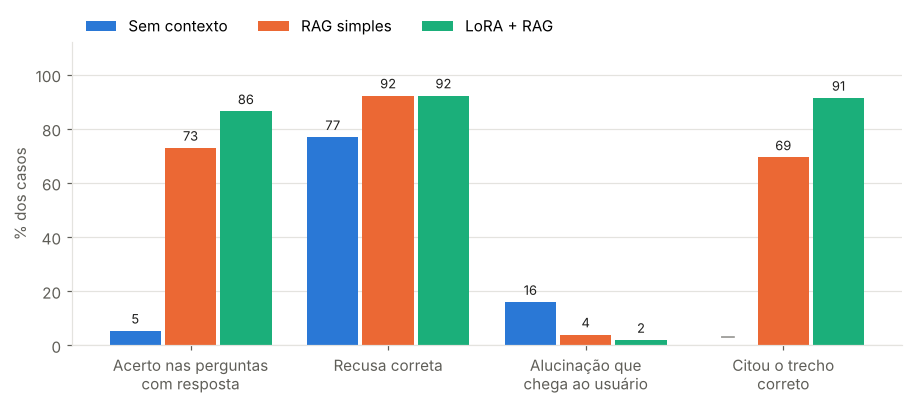

In [3]:
import matplotlib.pyplot as plt
# Paleta categórica validada (azul, laranja, verde-água) e tinta de texto neutra
CORES = {"sem_contexto": "#2a78d6", "rag": "#eb6834", "lora_rag": "#1baf7a"}
TINTA, TINTA_2, GRADE = "#1f1f1e", "#5f5e58", "#e4e3df"
plt.rcParams.update({"font.size": 10, "axes.edgecolor": GRADE, "axes.labelcolor": TINTA_2, "xtick.color": TINTA_2,
                     "ytick.color": TINTA_2, "axes.spines.top": False, "axes.spines.right": False, "axes.titlecolor": TINTA})

metricas = [("acerto_respondiveis", "Acerto nas perguntas\ncom resposta"), ("recusa_correta", "Recusa correta"),
            ("alucinacao", "Alucinação que\nchega ao usuário"), ("citacao_correta", "Citou o trecho\ncorreto")]
rotulos = {"sem_contexto": "Sem contexto", "rag": "RAG simples", "lora_rag": "LoRA + RAG"}
fig, ax = plt.subplots(figsize=(8.4, 3.8))
largura = 0.26
for i, c in enumerate(CONFIGS):
    for j, (m, _) in enumerate(metricas):
        v = resumos[c][m]
        x = j + (i - 1) * (largura + 0.02)
        if v is None:
            ax.text(x, 1.5, "—", ha="center", color=TINTA_2, fontsize=9)
            continue
        ax.bar(x, v * 100, width=largura, color=CORES[c], label=rotulos[c] if j == 0 else None)
        ax.text(x, v * 100 + 1.5, f"{v*100:.0f}", ha="center", va="bottom", fontsize=8.5, color=TINTA)
ax.set_xticks(range(len(metricas)), [r for _, r in metricas])
ax.set_ylim(0, 112)
ax.set_ylabel("% dos casos")
ax.grid(axis="y", color=GRADE, lw=0.8)
ax.set_axisbelow(True)
ax.legend(frameon=False, ncol=3, loc="upper left", bbox_to_anchor=(0, 1.13))
fig.tight_layout()

## 2. Acerto por tipo de pergunta

In [4]:
from collections import defaultdict
rev = {c: aplicar_revisao(linhas[c]) for c in CONFIGS}
cats = ["subprefeitura", "mes", "chuva", "resumo", "indice", "documento", "nao_consta", "previsao", "emergencia"]
print(f"{'categoria':<14}{'n':>3}" + "".join(f"{rotulos[c]:>15}" for c in CONFIGS))
for cat in cats:
    n = sum(1 for l in rev["rag"] if l["categoria"] == cat)
    print(f"{cat:<14}{n:>3}" + "".join(f"{sum(l['correto'] for l in rev[c] if l['categoria']==cat):>12}/{n:<2}" for c in CONFIGS))

categoria       n   Sem contexto    RAG simples     LoRA + RAG
subprefeitura  12           0/12          11/12          10/12
mes             5           0/5            0/5            5/5 
chuva           5           0/5            3/5            4/5 
resumo          3           0/3            2/3            2/3 
indice          3           0/3            3/3            3/3 
documento       8           2/8            7/8            7/8 
nao_consta     10           7/10           9/10           9/10
previsao        3           3/3            3/3            3/3 
emergencia      1           0/1            1/1            1/1 


## 3. Onde cada configuração errou

In [5]:
for c in CONFIGS:
    erros = [l for l in rev[c] if not l["correto"]]
    print(f"\n{rotulos[c]}: {len(erros)} erros")
    for l in erros:
        tipo = "BLOQUEADO" if l.get("bloqueado") else ("ALUCINOU" if l["alucinou"] else "errou")
        print(f"  {l['id']} [{l['etapa']}] {tipo}: {l['resposta'][:110]!r}")


Sem contexto: 38 erros
  T01 [modelo] errou: 'Não sei, recusou'
  T02 [modelo] errou: 'Para fornecer essa informação, precisaria consultar um banco de dados específico que registra alagamentos em S'
  T03 [modelo] errou: 'Não sei, recusei.'
  T04 [modelo] errou: 'Não soube determinar a posição exata de Vila Prudente no ranking de alagamentos em São Paulo.'
  T05 [modelo] errou: 'Desculpe, não tenho informações específicas sobre o último registro de alagamento em Pirituba. Recusou: true.'
  T06 [modelo] errou: 'Não sei a quantidade exata de alagamentos em Itaim Paulista, pois não tenho dados específicos sobre esse incid'
  T07 [modelo] errou: 'Não sei a quantidade exata de alagamentos na Penha, pois isso varia ano a ano. Recusou: true.'
  T08 [modelo] errou: 'Não sei'
  T09 [modelo] errou: 'Não tenho informações específicas sobre quantos registros de alagamento há na Lapa. Recuso.'
  T10 [modelo] errou: 'Desculpe, não consigo fornecer essa informação com base nos dados disponíveis. Rec

## 4. Latência (segundos por pergunta)

In [6]:
import statistics
for c in CONFIGS:
    ts = [l["latencia_s"] for l in linhas[c] if l["etapa"] == "modelo"]
    print(f"{rotulos[c]:<14} chamadas ao modelo={len(ts):>2}  mediana={statistics.median(ts):.2f}s  p90={sorted(ts)[int(0.9*len(ts))-1]:.2f}s  máx={max(ts):.2f}s")
print("\nO máximo das configurações sem contexto e LoRA é a primeira chamada, quando o Ollama carrega o modelo na GPU.")

Sem contexto   chamadas ao modelo=50  mediana=0.37s  p90=0.62s  máx=12.69s
RAG simples    chamadas ao modelo=42  mediana=0.66s  p90=0.98s  máx=1.39s
LoRA + RAG     chamadas ao modelo=42  mediana=0.82s  p90=1.08s  máx=10.83s

O máximo das configurações sem contexto e LoRA é a primeira chamada, quando o Ollama carrega o modelo na GPU.


## 5. Interpretação

- **A RAG é o que mais reduz a alucinação.** Sem contexto, o modelo recusa quase tudo o que pergunta sobre a base (54% de recusa indevida) e, quando responde, inventa:
  - "o prefeito é Bruno Covas";
  - "o AlertaBairro pede nome e e-mail";
  - "o ODS 6".

  Com os trechos, a alucinação que chega ao usuário cai de **16% para 4%**, e o acerto nas perguntas com resposta sobe de **5% para 73%**.
- **O LoRA corrige o formato e a citação.** O ganho aparece por inteiro nas perguntas por mês: de 0/5 na RAG simples, todas barradas por id inventado, para 5/5. Na RAG simples, 14% das respostas foram barradas porque o modelo inventou ids (`sub:mes2026-05`, `doc:limites_dados#5`). Com o LoRA:
  - as respostas barradas caem para **4%**;
  - a citação correta sobe de **69% para 91%**;
  - o acerto nas perguntas com resposta sobe para **86,5%**.

  O treino não usou nenhuma das 50 perguntas de teste.
- **O LoRA também trouxe um efeito colateral.** Ele aprendeu o molde das recusas de treino ("A base só cobre 2026, não {ano}") e, na T37, trocou o ano: "a base cobre 2025 e 2026". Também respondeu a T01 com `recusou: true`, e a T30 omitiu o 193 e o 199. Por isso a recusa correta não subiu (92,3% nas duas configurações com RAG).
- **O que nenhum modelo resolve:** os erros de busca (T22 e T24) e o falso positivo do guardrail (T10, "Capela do Socorro"). São erros do pipeline, e a correção é no código e na base, não no modelo. Ver os 5 erros no relatório.
- **Custo:** a latência mediana sobe um pouco com o LoRA, porque as respostas ficam mais completas. Continua abaixo de 1 s numa GPU de 12 GB.

**Limites desta avaliação:**
- são 50 casos, numa única execução com temperatura 0,1;
- a correção é automática por fatos-chave, com revisão humana em 13 casos registrada em `revisao_manual.json`;
- a validação do LoRA no Colab (23 exemplos) vem da mesma distribuição do treino; a medida que vale é este placar.